In [241]:
import numpy as np
import matplotlib.pyplot as plt
import json
import pandas as pd
from matplotlib.ticker import MaxNLocator
import matplotlib.cm as cm
import matplotlib.ticker as ticker


In [80]:


file_name = np.array([
    "R134a_emimtfsi_160_480_215",
    "R134a_emimtfsi_320_320_422",
    "R134a_emimtfsi_598_256_573",
    "R134a_emimtfsi_1088_192_646",
    "R134a_emimtfsi_1294_128_656",
    "R32_emimtfsi_160_480_293",
    "R32_emimtfsi_320_320_721",
    "R32_emimtfsi_598_256_1171",
    "R32_emimtfsi_1088_192_1512",
    "R32_emimtfsi_2048_86_1653"
])


hfc_array = np.array([
    "HFC-134a", "HFC-134a", "HFC-134a", "HFC-134a", "HFC-134a", 
    "HFC-32", "HFC-32", "HFC-32", "HFC-32", "HFC-32"
])


title_labels = np.array([
    "$x_{HFC-134a}$ = 0.25", "$x_{HFC-134a}$ = 0.50", "$x_{HFC-134a}$ = 0.70", 
    "$x_{HFC-134a}$ = 0.85", "$x_{HFC-134a}$ = 0.91", "$x_{HFC-32}$ = 0.25", 
    "$x_{HFC-32}$ = 0.50", "$x_{HFC-32}$ = 0.70", "$x_{HFC-32}$ = 0.85", 
    "$x_{HFC-32}$ = 0.96"
])


save_fig_labels = np.array([
    "25_R134a_n", "50_R134a_n", "70_R134a_n", "85_R134a_n", "91_R134a_n", 
    "25_R32_n", "50_R32_n", "70_R32_n", "85_R32_n", "96_R32_n"
])


In [81]:
def RDF_HFC_IL(file_id, hfc, title_label):    #    hfc = "R134a"   R134a_emimtfsi_1088_192_646_Diff_RDF_1.json
    openfile = open(f"{file_id}_Diff_RDF_1.json")
    dictionary = json.load(openfile)
    dict_items = dictionary.items()
    list_dictionary = list(dict_items)
    RDF_data = (((list_dictionary[3][1])))
    RDF_data = list(RDF_data.items())

    Radial_dist_emim_emim = RDF_data[0][1]
    Radial_dist_emim_tfsi = RDF_data[1][1]
    Radial_dist_hfc_emim = RDF_data[2][1]
    Radial_dist_hfc_hfc = RDF_data[3][1]
    Radial_dist_hfc_tfsi = RDF_data[4][1]
    Radial_dist_tfsi_tfsi = RDF_data[5][1]
    distance = RDF_data[6][1]

    Radial_dist_all = np.array([Radial_dist_emim_emim, Radial_dist_emim_tfsi, 
               Radial_dist_hfc_emim, Radial_dist_hfc_hfc,
               Radial_dist_hfc_tfsi, Radial_dist_tfsi_tfsi])

    rdf_labels = np.array(["EMIM-EMIM",
    "EMIM-TFSI",
    f"{hfc}-EMIM",
    f"{hfc}-{hfc}",
    f"{hfc}-TFSI",
    "TFSI-TFSI"])
    
    
    fig, ax = plt.subplots()
    
    for i in range(len(Radial_dist_all)):
        ax.plot(distance, Radial_dist_all[i], label = rdf_labels[i])
        plt.title(f"{title_label}")

    plt.legend()
    plt.yticks(fontsize=16)
    plt.xticks(fontsize=16)
    ax.minorticks_on()
    plt.xlabel(r' r $(\AA) $', fontsize=20)
    plt.ylabel(r'$ g(r) $', fontsize=20)
    plt.show()
    
    return plt.show()


In [82]:

# for i in range(len(file_name)):
#     print(i)
#     RDF_HFC_IL(file_name[i], hfc_array[i], title_labels[i])
    

In [83]:
def Get_cation_anion_RDF(file_id, hfc):    #    hfc = "R134a"   R134a_emimtfsi_1088_192_646_Diff_RDF_1.json
    openfile = open(f"{file_id}_Diff_RDF_1.json")
    dictionary = json.load(openfile)
    dict_items = dictionary.items()
    list_dictionary = list(dict_items)
    RDF_data = (((list_dictionary[3][1])))
    RDF_data = list(RDF_data.items())

    Radial_dist_emim_tfsi = RDF_data[1][1]
    Radial_dist_hfc_emim = RDF_data[2][1]
    Radial_dist_hfc_hfc = RDF_data[3][1]
    Radial_dist_hfc_tfsi = RDF_data[4][1]

    distance = RDF_data[6][1]
    
    return distance, Radial_dist_emim_tfsi
    

In [124]:
def RDF_HFC_IL_reduced(file_id, hfc, title_label, show_legend, savefig_labels, ax, is_last):    #    hfc = "R134a"   R134a_emimtfsi_1088_192_646_Diff_RDF_1.json
    openfile = open(f"{file_id}_Diff_RDF_1.json")
    dictionary = json.load(openfile)
    dict_items = dictionary.items()
    list_dictionary = list(dict_items)
    RDF_data = (((list_dictionary[3][1])))
    RDF_data = list(RDF_data.items())

    Radial_dist_emim_tfsi = RDF_data[1][1]
    Radial_dist_hfc_emim = RDF_data[2][1]
    Radial_dist_hfc_hfc = RDF_data[3][1]
    Radial_dist_hfc_tfsi = RDF_data[4][1]
    Radial_dist_tfsi_hfc = RDF_data[4][1]

    distance = RDF_data[6][1]

    Radial_dist_all = np.array([Radial_dist_emim_tfsi, 
               Radial_dist_hfc_emim, Radial_dist_hfc_hfc,
               Radial_dist_hfc_tfsi, Radial_dist_tfsi_hfc])
     #, Radial_dist_tfsi_hfc
    rdf_labels = np.array(["$[C_2C_1im]^+$ around $[TFSI]^-$",
    f"{hfc} around $[C_2C_1im]^+$",
    f"{hfc} around {hfc}",
    f"{hfc} around $[TFSI]^-$",
    f"$[TFSI]^-$  around {hfc}"])
    
    #fig, ax = plt.subplots()
    
    # Plot on the passed 'ax' instead of creating a new one
    for i in range(len(Radial_dist_all[0:-1])):
        ax.plot(distance, Radial_dist_all[i], label=rdf_labels[i])
        
        # Corner text
        ax.text(0.95, 0.05, title_label, transform=ax.transAxes, 
                fontsize=20, ha='right', va='bottom',
                bbox=dict(facecolor='white', alpha=0.5, edgecolor='none'))
    
        # Formatting
        if show_legend:
            ax.legend(loc='upper right')
            
        ax.yaxis.set_major_locator(MaxNLocator(integer=True))
        ax.tick_params(labelsize=16)
        ax.minorticks_on()
        ax.set_ylabel(r'$ g(r) $', fontsize=20)
        
        # Only show x-axis label and ticks on the bottom plot
        if is_last:
            ax.set_xlabel(r' r $(\AA) $', fontsize=20)
        else:
            # Hide x-axis labels for internal plots
            ax.tick_params(labelbottom=False)

        
    
    return Radial_dist_all, distance

    

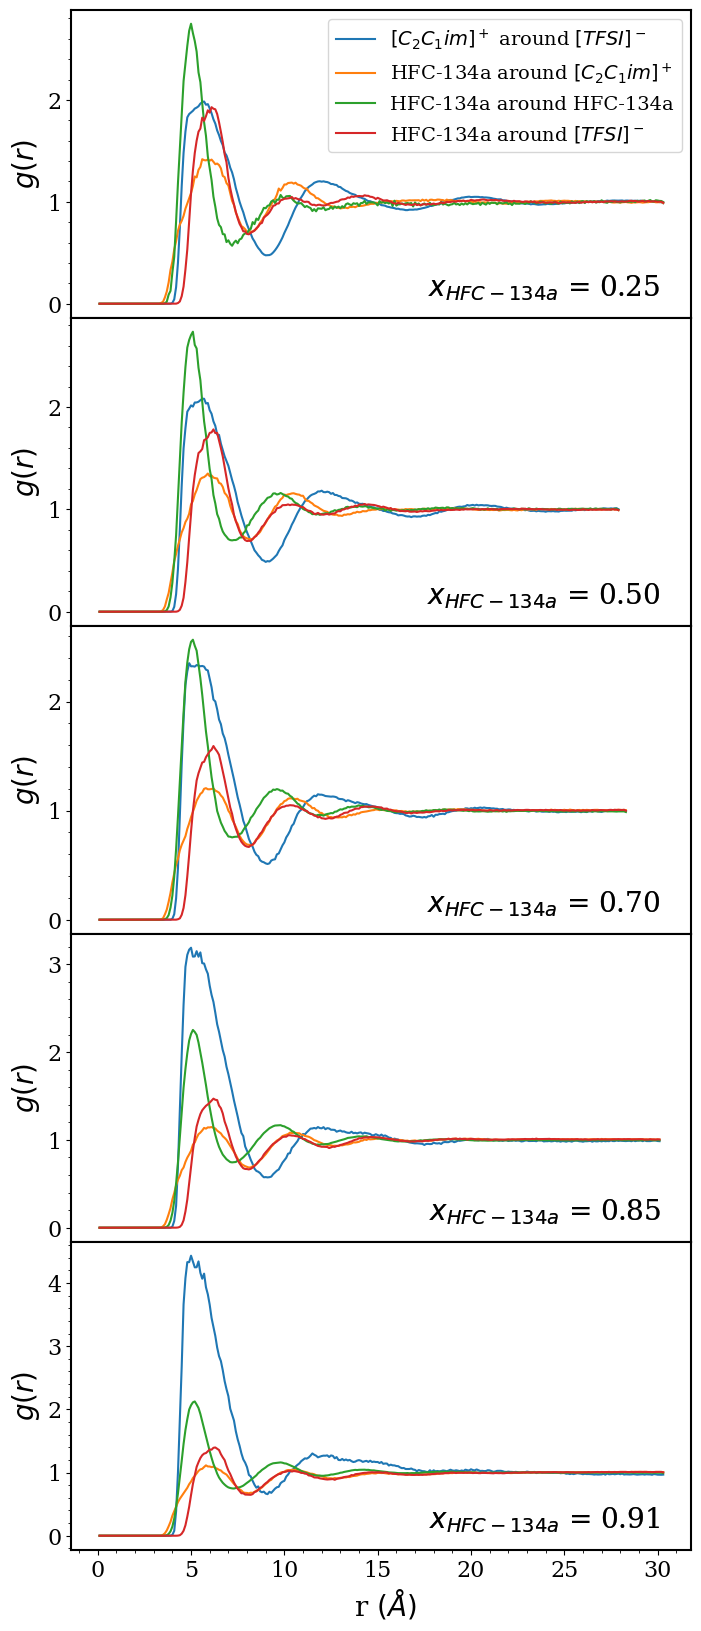

In [125]:

plt.rcParams.update({
    "text.usetex": False, # Set to True if you have LaTeX installed
    "font.family": "serif",
    "font.size": 14,
    "axes.linewidth": 1.5
})

rdf_all = []
distance_all = []
start = 0
stop = 5
plots_len = int(stop - start)

# Create the figure once
fig, axes = plt.subplots(plots_len, 1, figsize=(8, 4 * plots_len), sharex=True)
plt.subplots_adjust(hspace=0) # Removes vertical space between plots

RDF_R134a = []
Dist_R134a = []

for i, name in enumerate(file_name[start:stop]):
    # Determine if this is the last plot to show the x-label
    is_last = (i == plots_len - 1)
    
    # Pass the specific axis from our grid into the function
    RDF_R134a_i = RDF_HFC_IL_reduced(name, hfc_array[i+start], title_labels[i+start], 
                       (i == 0), save_fig_labels[i+start], axes[i], is_last)
    RDF_R134a.append(RDF_R134a_i[0])
    Dist_R134a.append(RDF_R134a_i[1])

#plt.savefig("RDF_Plots_R134a.png", dpi=300, bbox_inches='tight')


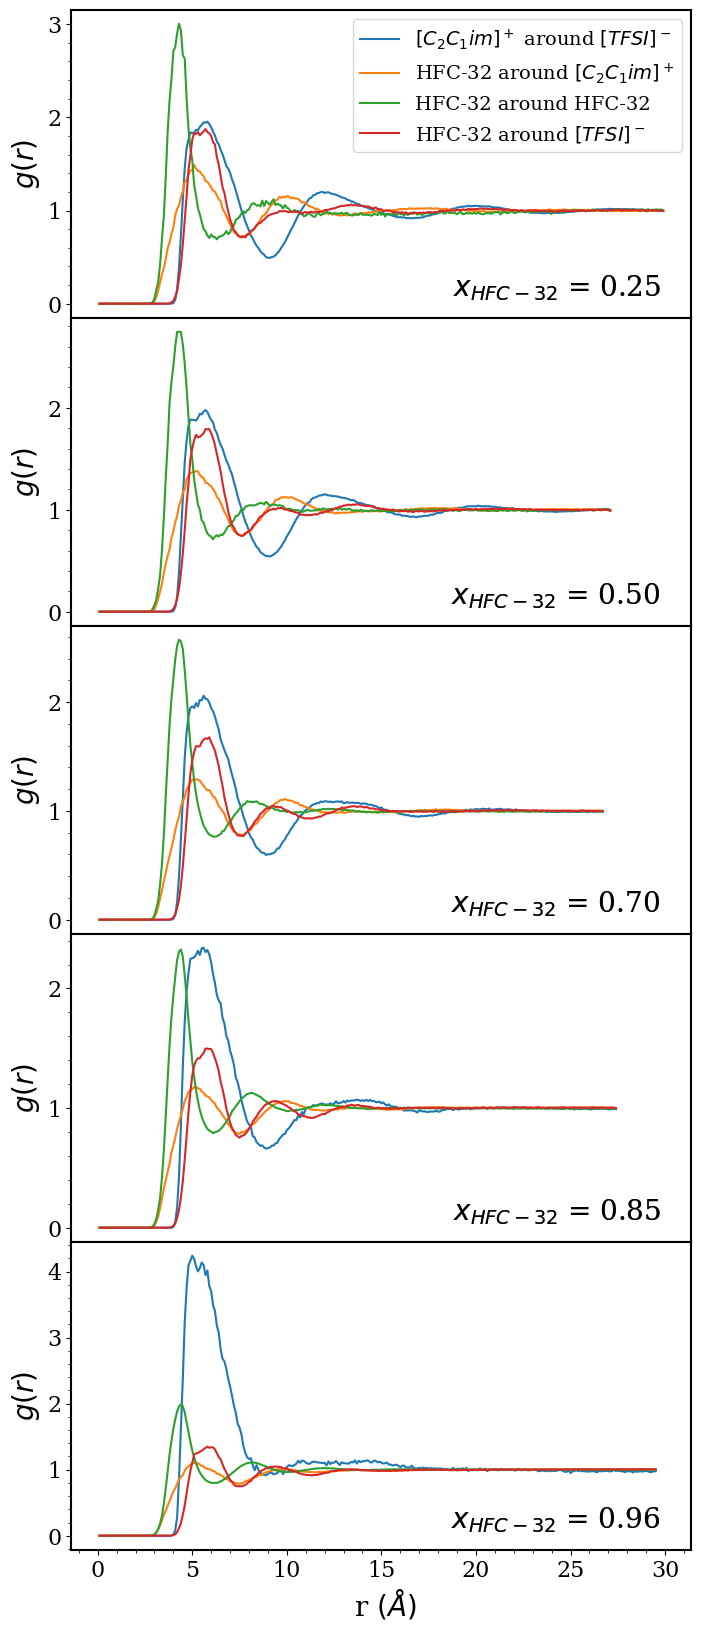

In [105]:
plt.rcParams.update({
    "text.usetex": False, # Set to True if you have LaTeX installed
    "font.family": "serif",
    "font.size": 14,
    "axes.linewidth": 1.5
})

rdf_all = []
distance_all = []
start = 5
stop = len(file_name)
plots_len = int(stop - start)

# Create the figure once
fig, axes = plt.subplots(plots_len, 1, figsize=(8, 4 * plots_len), sharex=True)
plt.subplots_adjust(hspace=0) # Removes vertical space between plots

RDF_R32 = []
Dist_R32 = []

for i, name in enumerate(file_name[start:stop]):
    # Determine if this is the last plot to show the x-label
    is_last = (i == plots_len - 1)
    
    # Pass the specific axis from our grid into the function
    RDF_R32_i = RDF_HFC_IL_reduced(name, hfc_array[i+start], title_labels[i+start], 
                       (i == 0), save_fig_labels[i+start], axes[i], is_last)
    RDF_R32.append(RDF_R32_i[0])
    Dist_R32.append(RDF_R32_i[1])

#plt.savefig("RDF_Plots_R32.png", dpi=300, bbox_inches='tight')
        

In [106]:
def find_RDF_minima(distance, RDF):
    ref_points = []
    for i in range(len(RDF)-1):
        if i == 0:
            continue
        else:
            if RDF[i] >= 1 and RDF[i-1] < 1:
                ref_points.append(i)
    start_index = ref_points[0]
    stop_index = ref_points[2]
    RDF_array = RDF[start_index:stop_index]
    first_minima = min(RDF_array)
    first_minima_index = np.where(RDF == first_minima)[0] #np.argmin(RDF[start_index:stop_index]) #RDF.index(first_minima)
    first_minima_index = int(first_minima_index[0])
    minima_pos = distance[first_minima_index]
    return minima_pos, first_minima, first_minima_index

In [114]:
len(RDF_R32[0])

5

In [134]:
num_rdf = 5

start = 0
stop = 5
#stop = len(file_name)
rdf_comps = int(stop - start)


R134a_rdf_minima = np.zeros([rdf_comps, num_rdf])
R134a_dist_minima = np.zeros([rdf_comps, num_rdf])
R134a_index_minima = np.zeros([rdf_comps, num_rdf])

rdf_all = RDF_R134a
distance_all = Dist_R134a

for i in range(rdf_comps):
    for j in range(num_rdf):
        rdf_ = rdf_all[i][j]
        distance_ = distance_all[i]
        minima_ = find_RDF_minima(distance_, rdf_)
        R134a_dist_minima[i,j] = minima_[0]
        R134a_rdf_minima[i,j] = minima_[1]
        R134a_index_minima[i,j] = minima_[2]
        
print(R134a_rdf_minima)
print()
print(R134a_dist_minima)        
        

[[0.47516998 0.69853728 0.56864258 0.68110163 0.68110163]
 [0.48677773 0.70671318 0.69678611 0.69046403 0.69046403]
 [0.5109319  0.68428934 0.7547802  0.66691247 0.66691247]
 [0.57306339 0.68537829 0.74395787 0.66368399 0.66368399]
 [0.65787987 0.67052663 0.74669697 0.64740155 0.64740155]]

[[9.  8.1 7.2 8.1 8.1]
 [9.  8.3 7.2 8.  8. ]
 [9.1 8.3 7.2 8.1 8.1]
 [9.1 8.1 7.2 8.1 8.1]
 [9.1 8.1 7.3 8.2 8.2]]


In [135]:

num_rdf = 5

start = 5
stop = len(file_name)
#stop = len(file_name)
rdf_comps = int(stop - start)


R32_rdf_minima = np.zeros([rdf_comps, num_rdf])
R32_dist_minima = np.zeros([rdf_comps, num_rdf])
R32_index_minima = np.zeros([rdf_comps, num_rdf])

rdf_all = RDF_R32
distance_all = Dist_R32

for i in range(rdf_comps):
    for j in range(num_rdf):
        rdf_ = rdf_all[i][j]
        distance_ = distance_all[i]
        minima_ = find_RDF_minima(distance_, rdf_)
        R32_dist_minima[i,j] = minima_[0]
        R32_rdf_minima[i,j] = minima_[1]
        R32_index_minima[i,j] = minima_[2]
        
print(R32_rdf_minima)
print()
print(R32_dist_minima)        
        


[[0.49150773 0.71159681 0.69032432 0.71123315 0.71123315]
 [0.54137725 0.74656762 0.71057519 0.74246    0.74246   ]
 [0.59514295 0.77650842 0.76340905 0.76906798 0.76906798]
 [0.66026886 0.78532125 0.79048048 0.7520265  0.7520265 ]
 [0.91398032 0.78531142 0.79877695 0.74795283 0.74795283]]

[[9.1 7.8 6.3 7.6 7.6]
 [9.1 7.7 6.1 7.6 7.6]
 [8.9 7.6 6.2 7.7 7.7]
 [8.9 7.5 6.1 7.5 7.5]
 [8.9 7.5 6.3 7.6 7.6]]


In [136]:
def CN_HFC_IL(file_id_array, pairs_id, cut_off_distance_array):    #    hfc = "R134a"   R134a_emimtfsi_1088_192_646_Diff_RDF_1.json
    CN_data_name_2Darray = []
    #CN_data_firstminima_2Darray = []
    CN_data_integral_3Darray = []
    
    for j in range(len(file_id_array)):
        openfile = open(f"{file_id_array[j]}_Diff_RDF_1.json")
        dictionary = json.load(openfile)
        dict_items = dictionary.items()
        list_dictionary = list(dict_items)
        CN_data_all = list((list_dictionary[0][1]).items())
    
        CN_data_name_array = []
        #CN_data_firstminima_array = []
        CN_data_integral_array = []
        for i in pairs_id:
            CN_data_name = CN_data_all[i][0]
            CN_data_name_array.append(CN_data_name)
            CN_data_main = list((CN_data_all[i][1]).items())
            #CN_data_firstminima = CN_data_main[2][1][0]
            #CN_data_firstminima_array.append(CN_data_firstminima)
            CN_data_integral = CN_data_main[1][1]
            CN_data_integral_array.append(CN_data_integral)
    
        CN_data_name_2Darray.append(CN_data_name_array)
        #CN_data_firstminima_2Darray.append(CN_data_firstminima_array)
        CN_data_integral_3Darray.append(CN_data_integral_array)
    
    
    CN_data_name_2Darray = np.array(CN_data_name_2Darray, dtype=object)
    #CN_data_firstminima_2Darray = np.array(CN_data_firstminima_2Darray, dtype=object)
    CN_data_integral_3Darray = np.array(CN_data_integral_3Darray, dtype=object)
    
    #max_minima = np.amax(CN_data_firstminima_2Darray.astype(float))
    #max_minima_pos = np.argmax(CN_data_firstminima_2Darray.astype(float))

    CN_value_2D_array = np.empty((len(file_id_array), len(pairs_id)))
    for k in range(len(file_id_array)):
        for l in range(len(pairs_id)):
            cut_off_distance = cut_off_distance_array[k,l]
            index_cumulintegral = int(cut_off_distance/0.1 - 1)
            CN_array = CN_data_integral_3Darray[k, l]
            CN_value = CN_array[index_cumulintegral]
            CN_value_2D_array[k, l] = CN_value

    return CN_data_name_2Darray, CN_value_2D_array


In [140]:

file_name_R32_o = np.array(["R32_emimtfsi_2048_86_1653",
"R32_emimtfsi_1088_192_1512",
"R32_emimtfsi_598_256_1171",
"R32_emimtfsi_320_320_721",
"R32_emimtfsi_160_480_293"])
file_name_R32 = file_name_R32_o[::-1]



file_name_R134a_o = np.array([
"R134a_emimtfsi_1294_128_656",
"R134a_emimtfsi_1088_192_646",
"R134a_emimtfsi_598_256_573",
"R134a_emimtfsi_320_320_422",
"R134a_emimtfsi_160_480_215"])
file_name_R134a = file_name_R134a_o[::-1]

pairs_id = [2, 3, 4, 5, 7] 
comp_array_R32_o = [0.96, 0.85, 0.70, 0.50, 0.25]
comp_array_R32 = comp_array_R32_o[::-1]
comp_array_R134a_o = [0.91, 0.85, 0.70, 0.50, 0.25]
comp_array_R134a = comp_array_R134a_o[::-1]


In [141]:
#dist_minima[0:5, :]

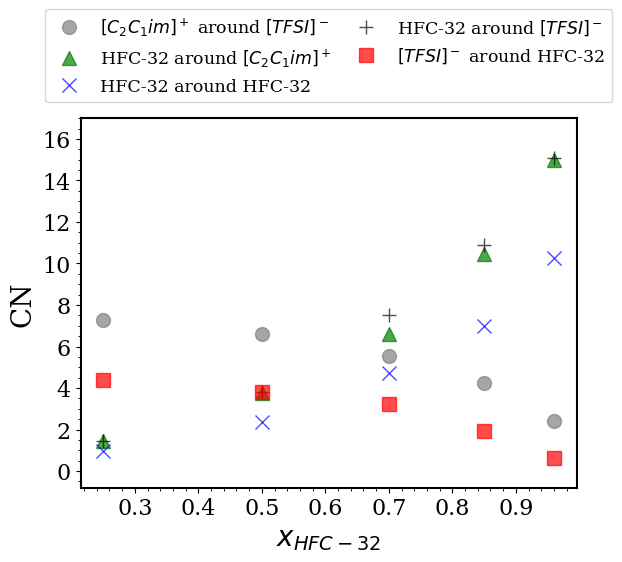

In [164]:

CN_R32_all = CN_HFC_IL(file_name_R32, pairs_id, R32_dist_minima)
CN_R32 = CN_R32_all[-1]
CN_R32_names = CN_R32_all[0][0,:]


replacements = {
    "EMIM": "$[C_2C_1im]^+$",
    "TFSI": "$[TFSI]^-$",
    "R32": "HFC-32",
    "R134a": "HFC-134a"
}


def format_label(label):
    for old, new in replacements.items():
        label = label.replace(old, new)
    return label

CN_R32_names = np.array([format_label(name) for name in CN_R32_names])


markers_id = [ 'o', '^', 'x', '+', 's']
color_id = [ 'gray', 'green', 'blue', 'black', 'red']





fig, ax = plt.subplots()
for p in range(len(CN_R32_names)):
    #print(CN_R32_names[p])
    plt.plot(comp_array_R32, CN_R32[:,p], label=f'{CN_R32_names[p]}', marker=markers_id[p], \
             linestyle='', markersize=10, alpha=0.7, color=color_id[p])
ax.legend(bbox_to_anchor=(-0.09, 1.02, 1.18, 0.3), loc="lower left", mode="expand", ncol=2, fontsize=12.5)
plt.yticks(fontsize=16)
plt.xticks(fontsize=16)
ax.minorticks_on()
plt.ylim(-0.8, 17)
plt.xlabel(r'$x_{HFC-32}$', fontsize=20)
plt.ylabel(f'CN', fontsize=20)
#plt.title()
#plt.show()
plt.savefig(f"R32_emimtfsi_CN_n", dpi=300, bbox_inches='tight')


In [146]:
print(CN_R32_names)


['EMIM around TFSI' 'R32 around EMIM' 'R32 around R32' 'R32 around TFSI'
 'TFSI around R32']


In [234]:
CN_R32

array([[ 7.27122006,  1.45310421,  0.95805888,  1.45521873,  4.36565619],
       [ 6.6243357 ,  3.74703406,  2.38423777,  3.82339384,  3.82339384],
       [ 5.56226219,  6.58444439,  4.71543535,  7.52186642,  3.22006322],
       [ 4.25260417, 10.43267112,  7.00668332, 10.90648911,  1.92467455],
       [ 2.40496913, 14.97017593, 10.27592666, 15.08636216,  0.63350935]])

In [235]:
CN_R134a

array([[ 7.0530647 ,  1.52897538,  1.31578094,  1.6591255 ,  4.9773765 ],
       [ 6.16768026,  4.07559256,  3.54486028,  4.00243575,  4.00243575],
       [ 5.13668366,  6.7479728 ,  6.2588068 ,  6.47813358,  2.77324782],
       [ 3.8666833 ,  8.88434589,  8.62212157,  9.20649846,  1.6246762 ],
       [ 3.27361683, 10.04239958, 10.06666574, 10.65999251,  1.05446603]])

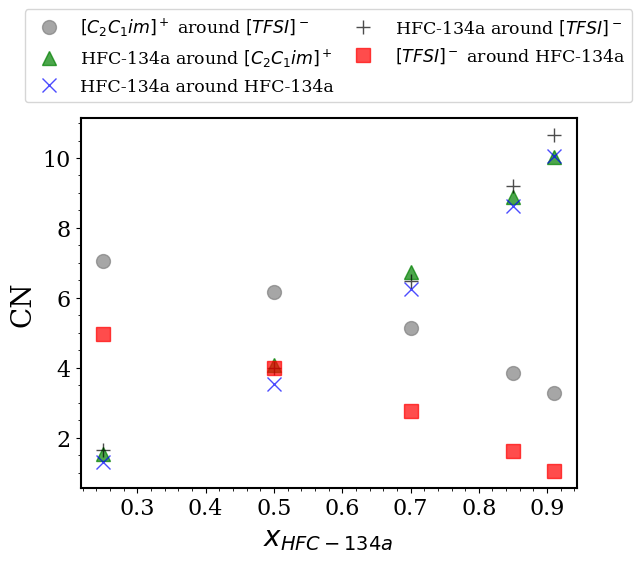

In [171]:

CN_R134a_all = CN_HFC_IL(file_name_R134a, pairs_id, R134a_dist_minima)
CN_R134a = CN_R134a_all[-1]
CN_R134a_names = CN_R134a_all[0][0,:]

CN_R134a_names = np.array([format_label(name) for name in CN_R134a_names])


markers_id = [ 'o', '^', 'x', '+', 's']
color_id = [ 'gray', 'green', 'blue', 'black', 'red']





fig, ax = plt.subplots()
for p in range(len(CN_R134a_names)):
    #print(CN_R134a_names[p])
    plt.plot(comp_array_R134a, CN_R134a[:,p], label=f'{CN_R134a_names[p]}', marker=markers_id[p], \
             linestyle='', markersize=10, alpha=0.7, color=color_id[p])
ax.legend(bbox_to_anchor=(-0.13, 1.02, 1.26, 0.3), loc="lower left", mode="expand", ncol=2, fontsize=12.5)
plt.yticks(fontsize=16)
plt.xticks(fontsize=16)
ax.minorticks_on()
#plt.ylim(-0.8, 13)
plt.xlabel(r'$x_{HFC-134a}$', fontsize=20)
plt.ylabel(f'CN', fontsize=20)
#plt.title()
#plt.show()
plt.savefig(f"R134a_emimtfsi_CN_n", dpi=300, bbox_inches='tight')


## S(q) plots

In [196]:

file_name_R32_updated = np.concatenate([
    ["pure_emimtfsi_nil_300_100"], 
    file_name_R32, 
    ["R32_noIL_2000_0_1690"]
])
#print(file_name_R32_updated)

file_name_R134a_updated = np.concatenate([
    ["pure_emimtfsi_nil_300_100"], 
    file_name_R134a, 
    ["R134a_noIL_1000_0_665"]
])
#print(file_name_R134a_updated)



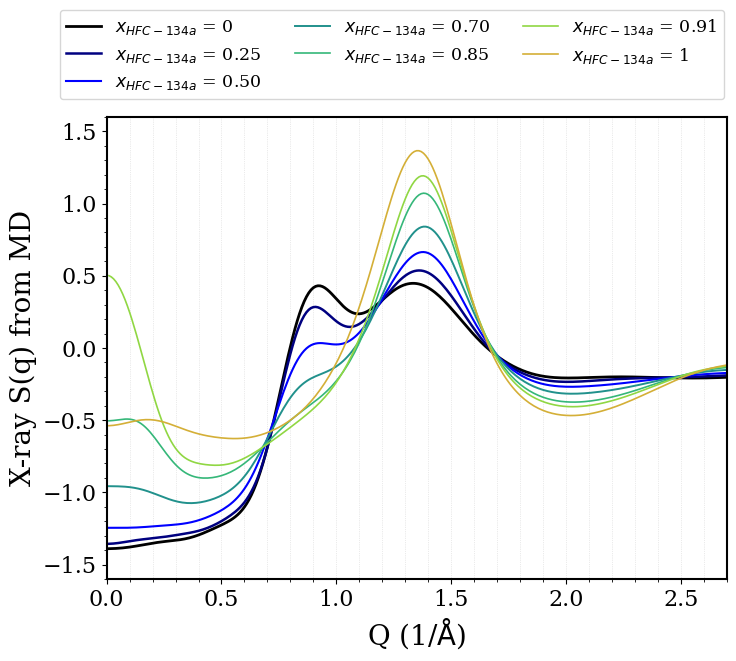

In [254]:

cutoff_index = 270
Sq_R134a = np.zeros([ int(cutoff_index), len(file_name_R134a_updated)])
q_R134a = np.zeros([ int(cutoff_index), len(file_name_R134a_updated)])
for i, name in enumerate(file_name_R134a_updated):
    Sq_dat_all = pd.read_csv(f"{name}_Sq_1.dat", sep=r'\s+', skiprows=1, header=None, engine='python')
    Sq_dat = Sq_dat_all.iloc[0:cutoff_index, 1]
    q_dat = Sq_dat_all.iloc[0:cutoff_index, 0]
    Sq_R134a[:,i] = Sq_dat
    q_R134a[:,i] = q_dat


colors = [
    '#000000', # Black
    '#000080', # Midnight blue
    '#0000FF', # Blue
    '#21918c', # Teal
    '#35b779', # Green
    '#90d743', # Light Green
    '#D4AF37' # gold
]


legends_ = [ '$x_{HFC-134a}$ = 0' , '$x_{HFC-134a}$ = 0.25' , '$x_{HFC-134a}$ = 0.50', '$x_{HFC-134a}$ = 0.70',
          '$x_{HFC-134a}$ = 0.85', '$x_{HFC-134a}$ = 0.91', '$x_{HFC-134a}$ = 1' ]

linewidth = [2.0, 1.8, 1.5, 1.4, 1.2, 1.2, 1.2]


plt.rcParams.update({
    "text.usetex": False, 
    "font.family": "serif",
    "font.size": 16,
    "axes.linewidth": 1.5
})


fig, ax = plt.subplots(figsize=(8, 6)) # Recommended to use ax for better control

for i in range(len(file_name_R134a_updated)):
    ax.plot(q_R134a[:, i], Sq_R134a[:, i], color=colors[i], label=legends_[i], linewidth=linewidth[i])


ax.xaxis.set_minor_locator(ticker.AutoMinorLocator())
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator())


ax.grid(visible=True, which='both', axis='x', linestyle=':', linewidth=0.5, alpha=0.5)

# --- Styling and Labels ---
ax.tick_params(axis='both', which='major', labelsize=16)
ax.set_xlim(0, q_R134a[-1, 0]) 
ax.set_ylim(-1.6, 1.6)

# Legend and Labels
ax.legend(bbox_to_anchor=(-0.09, 1.02, 1.1, 0.3), loc="lower left", 
           mode="expand", ncol=3, fontsize=12.5)
ax.set_xlabel(r"Q (1/$\mathrm{\AA}$)", fontsize=20) 
ax.set_ylabel(r"X-ray S(q) from MD", fontsize=20)

plt.savefig(f"R134a_emimtfsi_Sq_n", dpi=300, bbox_inches='tight')
plt.show()



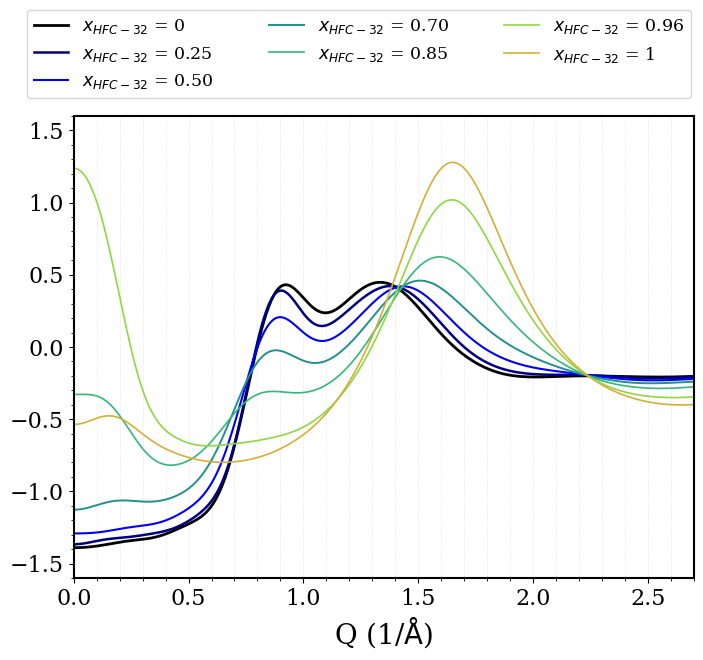

In [256]:

cutoff_index = 270
Sq_R32 = np.zeros([ int(cutoff_index), len(file_name_R32_updated)])
q_R32 = np.zeros([ int(cutoff_index), len(file_name_R32_updated)])
for i, name in enumerate(file_name_R32_updated):
    Sq_dat_all = pd.read_csv(f"{name}_Sq_1.dat", sep=r'\s+', skiprows=1, header=None, engine='python')
    Sq_dat = Sq_dat_all.iloc[0:cutoff_index, 1]
    q_dat = Sq_dat_all.iloc[0:cutoff_index, 0]
    Sq_R32[:,i] = Sq_dat
    q_R32[:,i] = q_dat


colors = [
    '#000000', # Black
    '#000080', # Midnight blue
    '#0000FF', # Blue
    '#21918c', # Teal
    '#35b779', # Green
    '#90d743', # Light Green
    '#D4AF37' # gold
]


legends_ = [ '$x_{HFC-32}$ = 0' , '$x_{HFC-32}$ = 0.25' , '$x_{HFC-32}$ = 0.50', '$x_{HFC-32}$ = 0.70',
          '$x_{HFC-32}$ = 0.85', '$x_{HFC-32}$ = 0.96', '$x_{HFC-32}$ = 1' ]

linewidth = [2.0, 1.8, 1.5, 1.4, 1.2, 1.2, 1.2]



plt.rcParams.update({
    "text.usetex": False, 
    "font.family": "serif",
    "font.size": 16,
    "axes.linewidth": 1.5
})


fig, ax = plt.subplots(figsize=(8, 6)) # Recommended to use ax for better control

for i in range(len(file_name_R32_updated)):
    ax.plot(q_R32[:, i], Sq_R32[:, i], color=colors[i], label=legends_[i], linewidth=linewidth[i])


ax.xaxis.set_minor_locator(ticker.AutoMinorLocator())
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator())


ax.grid(visible=True, which='both', axis='x', linestyle=':', linewidth=0.5, alpha=0.5)

# --- Styling and Labels ---
ax.tick_params(axis='both', which='major', labelsize=16)
ax.set_xlim(0, q_R32[-1, 0]) 
ax.set_ylim(-1.6, 1.6)

# Legend and Labels
ax.legend(bbox_to_anchor=(-0.09, 1.02, 1.1, 0.3), loc="lower left", 
           mode="expand", ncol=3, fontsize=12.5)
ax.set_xlabel(r"Q (1/$\mathrm{\AA}$)", fontsize=20) 
#ax.set_ylabel(r"X-ray S(q) from MD", fontsize=20)

plt.savefig(f"R32_emimtfsi_Sq_n", dpi=300, bbox_inches='tight')
plt.show()



In [184]:
Sq_check = pd.read_csv(
    "R32_emimtfsi_2048_86_1653_Sq_1.dat", 
    sep=r'\s+', 
    skiprows=1,      # Skip the header line manually
    header=None, 
    engine='python'  # The Python engine is more robust for regex and whitespace
)

In [189]:
Sq_check.head()

,0,1,2,3,4,5,6,7,8,9,...,128,129,130,131,132,133,134,135,136,137
0,0.01,1.236301,0.021874,0.652606,0.072545,-0.093955,-0.046846,-0.007801,-0.015446,-0.109626,...,0.746548,0.192718,0.521806,0.115108,0.026799,0.117359,0.025902,0.201916,0.070623,0.004423
1,0.02,1.229590,0.021490,0.651434,0.072412,-0.093727,-0.046728,-0.007782,-0.015405,-0.109361,...,0.744247,0.192217,0.520487,0.114820,0.026690,0.117077,0.025841,0.201215,0.070476,0.004393
2,0.03,1.218354,0.020843,0.649458,0.072187,-0.093345,-0.046531,-0.007750,-0.015336,-0.108917,...,0.740397,0.191379,0.518277,0.114338,0.026509,0.116604,0.025738,0.200038,0.070228,0.004343
3,0.04,1.202522,0.019921,0.646645,0.071868,-0.092805,-0.046252,-0.007705,-0.015240,-0.108291,...,0.734981,0.190199,0.515164,0.113659,0.026254,0.115937,0.025594,0.198376,0.069878,0.004272
4,0.05,1.182008,0.018711,0.642954,0.071450,-0.092105,-0.045891,-0.007647,-0.015115,-0.107478,...,0.727979,0.188672,0.511130,0.112778,0.025923,0.115071,0.025407,0.196216,0.069423,0.004180
